# 🧠 Deep Learning — Concept-to-Project Complete Notebook

এই notebook দুইটা অংশে ভাগ করা:

**PART A — ML Basics (Real Dataset দিয়ে)**
Kaggle-এর **Pima Indians Diabetes Dataset** (768 patient, বিভিন্ন medical measurement দিয়ে
diabetes আছে কিনা predict করা — Binary Classification) দিয়ে EDA + Visualization।

**PART B — DL Fundamentals (Concept demo, ছোট toy example দিয়ে)**
তুমি যা যা শিখেছ (Perceptron → Autograd) প্রতিটা টপিক এখানে আলাদা section-এ, code সহ recap।
এইখানে real dataset ব্যবহার হচ্ছে না ইচ্ছাকৃতভাবে — কারণ concept গুলো (যেমন AND/XOR, Decision
Boundary) ছোট, controlled data দিয়ে বোঝা সবচেয়ে সহজ।

**PART C — Full Real-World Project (Diabetes Dataset + Complete Pipeline)**
এই অংশে PART A-এর dataset দিয়েই একটা সম্পূর্ণ, production-style `nn.Module` MLP training
pipeline বানানো হচ্ছে — Preprocessing → DataLoader → Model → Training Loop → Complex
Visualization (loss curve, decision boundary, ROC curve, confusion matrix) → Evaluation → Save।

**কেন এই structure?** যাতে বুঝতে পারো — PART B-এর "hand-written" concept গুলোই আসলে PART C-এ
`nn.Module`, `optimizer.step()`, `loss.backward()`-এর ভেতরে automatic ভাবে ঘটছে।


---
# PART A — ML Basics: Data Load, EDA, Visualization

## A.1 Import Libraries


In [ ]:
# ===== Data handling =====
import numpy as np              # numerical array/matrix operation-এর জন্য (mean, std, array math ইত্যাদি)
import pandas as pd             # CSV file load করা এবং tabular data নিয়ে কাজ করার জন্য (DataFrame)

# ===== Visualization =====
import matplotlib.pyplot as plt # basic plotting (line, scatter, bar chart)
import seaborn as sns           # matplotlib-এর উপরে বানানো, সুন্দর statistical plot (heatmap, pairplot) সহজে করা যায়

# ===== ML preprocessing/metrics (sklearn) =====
from sklearn.model_selection import train_test_split         # data-কে train/val/test-এ ভাগ করার জন্য
from sklearn.preprocessing import StandardScaler              # feature-গুলোকে একই scale-এ আনার জন্য (mean=0, std=1)
from sklearn.decomposition import PCA                         # high-dimensional data-কে 2D-তে কমিয়ে visualize করার জন্য
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,  # classification metrics
    confusion_matrix, roc_curve, auc                          # confusion matrix + ROC curve-এর জন্য
)

# ===== Deep Learning (PyTorch) =====
import torch                          # PyTorch-এর মূল library — tensor ও computation-এর জন্য
import torch.nn as nn                 # Neural network layer/loss তৈরির জন্য (nn.Linear, nn.BCELoss ইত্যাদি)
import torch.optim as optim           # Optimizer-এর জন্য (SGD, Adam)
from torch.utils.data import TensorDataset, DataLoader  # data-কে batch আকারে model-এ পাঠানোর জন্য

# Reproducibility — random seed fix করা হচ্ছে
# কারণ: torch এবং numpy দুটোই ভেতরে random number ব্যবহার করে (weight initialization, shuffling ইত্যাদিতে)
# seed fix না করলে প্রতিবার notebook run করলে ভিন্ন ভিন্ন result আসবে, যা debug/compare করা কঠিন করে তোলে
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print("Setup complete. PyTorch version:", torch.__version__)


Setup complete. PyTorch version: 2.13.0+cu130


## A.2 Data Load

Dataset-এ কোনো header (column name) নেই, তাই manually column নাম বসিয়ে দিতে হচ্ছে।

In [ ]:
# ডেটাসেটের প্রতিটা column আসলে কী represent করে, সেই অনুযায়ী নাম বসানো হচ্ছে
# (এই dataset-টা raw অবস্থায় আসে, header ছাড়া — তাই আমাদেরই নাম বসাতে হবে)
column_names = [
    "Pregnancies",       # কতবার pregnant হয়েছেন
    "Glucose",           # blood glucose level
    "BloodPressure",     # blood pressure (mm Hg)
    "SkinThickness",     # skin fold thickness (mm)
    "Insulin",           # insulin level
    "BMI",               # Body Mass Index
    "DiabetesPedigreeFunction",  # পারিবারিক history অনুযায়ী diabetes risk score
    "Age",               # বয়স
    "Outcome"            # Target column: 1 = diabetes আছে, 0 = নেই (এটাই আমরা predict করব)
]

# pd.read_csv দিয়ে CSV file-কে DataFrame হিসেবে load করা হচ্ছে
# header=None বলা হচ্ছে কারণ file-এ কোনো column name নেই (raw data)
# names=column_names দিয়ে আমাদের বানানো নাম গুলো বসিয়ে দেওয়া হচ্ছে
df = pd.read_csv("diabetes_raw.csv", header=None, names=column_names)

# প্রথম ৫টা row দেখে data-র structure বোঝা
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## A.3 Basic EDA (Exploratory Data Analysis)

In [ ]:
# dataset-এর shape দেখা — (row_count, column_count)
print("Dataset shape:", df.shape)

# প্রতিটা column-এর data type দেখা (সব numeric হওয়া উচিত এই dataset-এ)
print("\nColumn dtypes:\n", df.dtypes)


Dataset shape: (768, 9)

Column dtypes:
 Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [ ]:
# Missing value (NaN) আছে কিনা চেক করা
print("Missing values per column:\n", df.isnull().sum())

# লক্ষ্য করার বিষয়: এই dataset-এ সত্যিকারের missing value নেই (NaN নেই),
# কিন্তু বাস্তবে Glucose/BloodPressure/BMI = 0 হওয়াটা medically অসম্ভব
# (একজন জীবিত মানুষের glucose/blood pressure কখনো 0 হতে পারে না)
# তাই এই 0-গুলো আসলে "hidden missing value" — একটু পরেই সেটা চেক করব
zero_counts = (df[["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]] == 0).sum()
print("\n0 value counts (সম্ভাব্য hidden missing data):\n", zero_counts)


Missing values per column:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

0 value counts (সম্ভাব্য hidden missing data):
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [ ]:
# Statistical summary — min, max, mean, std, quartile দেখা
# এখান থেকেই বোঝা যায় feature-গুলোর scale কতটা ভিন্ন (Insulin 0-846, BMI 0-67)
# — এই ভিন্নতার কারণেই পরে StandardScaler লাগবে
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
# Target column (Outcome) balanced নাকি imbalanced তা দেখা
print("Class distribution:\n", df['Outcome'].value_counts())
print("\nPercentage:\n", df['Outcome'].value_counts(normalize=True) * 100)

# লক্ষ্য করো: এখানে ক্লাস কিছুটা imbalanced (0 বেশি, 1 কম)
# এটা মাথায় রাখা জরুরি, কারণ শুধু "accuracy" দেখলে ভুল ধারণা হতে পারে
# (যদি model সবসময় 0 predict করে, তাও অনেক ভালো accuracy দেখাবে — তাই precision/recall/F1 ও দেখা লাগবে)


Class distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64

Percentage:
 Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


## A.4 Basic Visualization

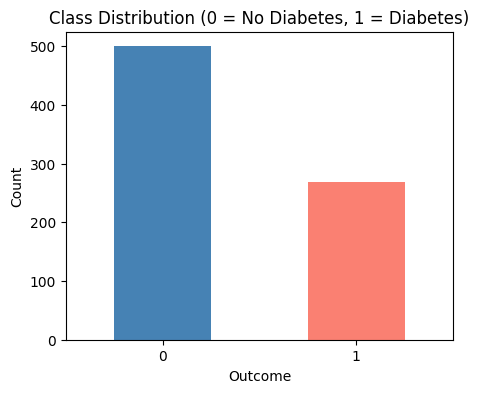

In [ ]:
# Class distribution bar chart দিয়ে visualize করা
plt.figure(figsize=(5, 4))
df['Outcome'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.title("Class Distribution (0 = No Diabetes, 1 = Diabetes)")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()


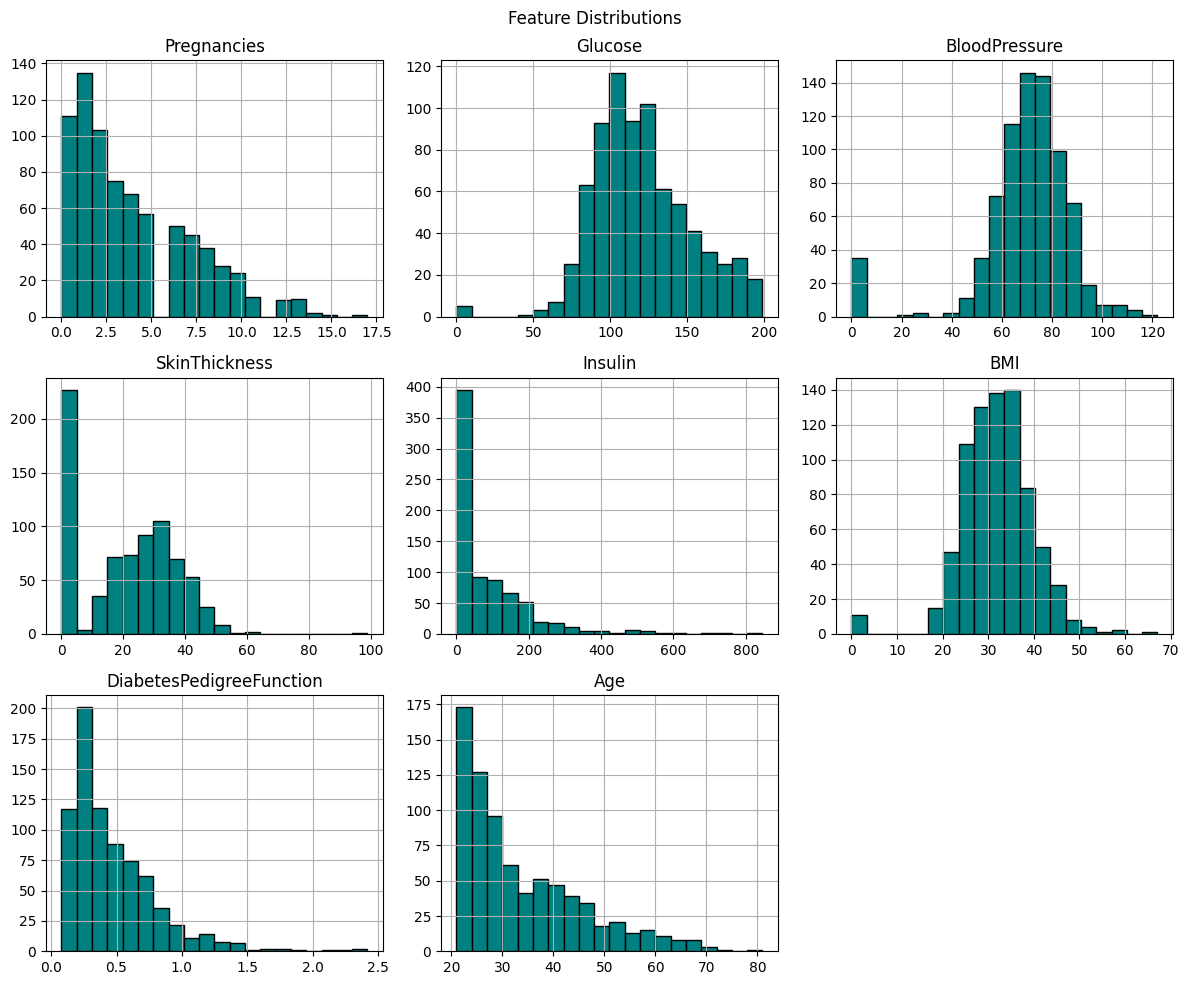

In [ ]:
# প্রতিটা feature-এর distribution (histogram) দেখা
# এতে বোঝা যায় কোনো feature skewed কিনা, outlier আছে কিনা
df.drop(columns=['Outcome']).hist(figsize=(12, 10), bins=20, color='teal', edgecolor='black')
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()


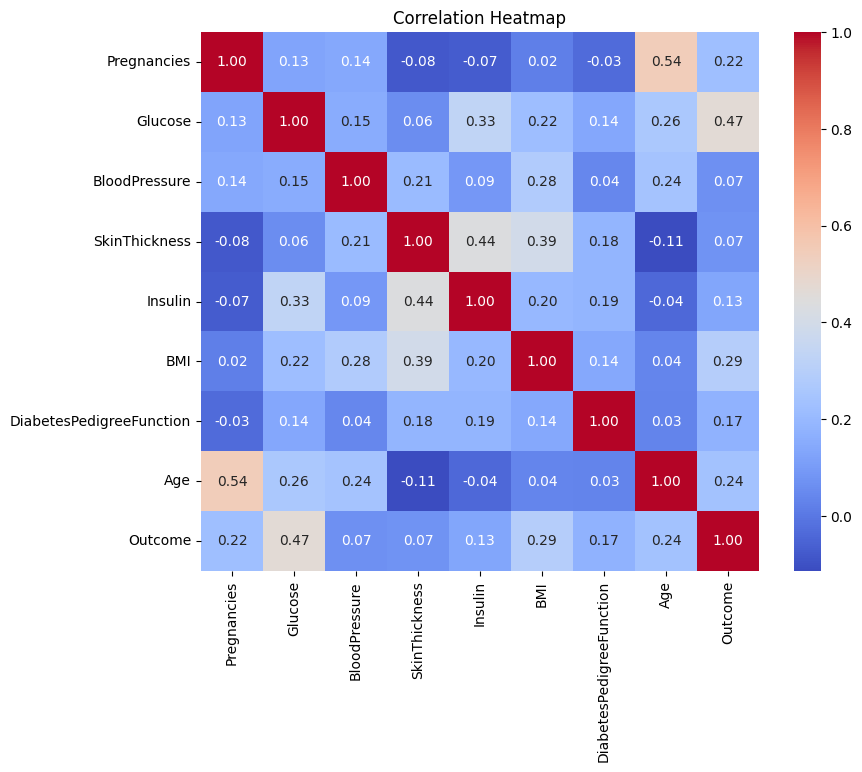

In [ ]:
# Correlation heatmap — কোন feature গুলো একে অপরের সাথে বা Outcome-এর সাথে
# বেশি সম্পর্কিত (linearly) তা দেখা
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

# লক্ষ্য করো: Glucose-এর সাথে Outcome-এর correlation সবচেয়ে বেশি —
# মানে diabetes prediction-এ Glucose সবচেয়ে গুরুত্বপূর্ণ feature হতে পারে


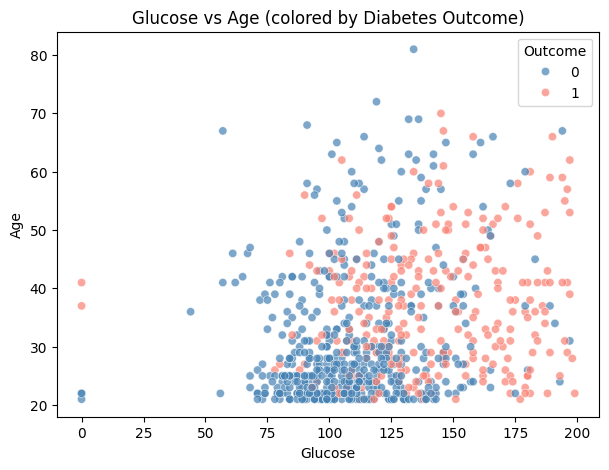

In [ ]:
# Glucose vs Age, class (Outcome) অনুযায়ী রঙ দিয়ে আলাদা করে scatter plot
# এতে visually বোঝা যায় দুই class কতটা আলাদা করা যায় (separable) এই দুই feature দিয়ে
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Glucose', y='Age', hue='Outcome', palette=['steelblue', 'salmon'], alpha=0.7)
plt.title("Glucose vs Age (colored by Diabetes Outcome)")
plt.show()


---
# PART B — Deep Learning Fundamentals (Concept Demos)

এই অংশে ছোট, controlled toy example দিয়ে প্রতিটা concept আলাদা করে দেখানো হচ্ছে —
real dataset না ব্যবহার করে, কারণ concept-গুলো ছোট data-তেই সবচেয়ে পরিষ্কার বোঝা যায়।


## B.1 Perceptron (Forward Pass)

একটামাত্র neuron — input নিয়ে weighted sum + bias বের করে, activation দিয়ে output দেয়।

In [ ]:
# একটা perceptron মানে হলো: output = activation(w·x + b)
w = torch.tensor([0.5, -0.3])   # weight — প্রতিটা input feature-এর গুরুত্ব বোঝায়
b = torch.tensor(0.1)           # bias — সব feature 0 হলেও output-কে shift করার জন্য
x = torch.tensor([1.0, 2.0])    # input feature (2টা feature ধরা হলো)

z = torch.dot(w, x) + b         # weighted sum + bias (raw score, "logit")
output = torch.sigmoid(z)       # activation function দিয়ে 0-1 এর মধ্যে চাপা (probability হিসেবে ব্যবহারযোগ্য)

print("z (raw score):", z.item())
print("output (after sigmoid):", output.item())


z (raw score): -2.2351741790771484e-08
output (after sigmoid): 0.5


## B.2 Weight Update (Manual)

Prediction ভুল হলে, error অনুযায়ী weight/bias hাতে (formula দিয়ে) update করা।

In [ ]:
w = torch.tensor([0.3, 0.7])
b = torch.tensor(0.1)
eta = 0.2   # learning rate — update কতটা বড় step-এ হবে তা নিয়ন্ত্রণ করে

x = torch.tensor([1.0, 1.0])
y_true = torch.tensor(0.0)      # আসল label

# ---- forward pass (update-এর আগে) ----
z = torch.dot(w, x) + b
y_pred = torch.sigmoid(z)
print("Before update -> w:", w.tolist(), "b:", b.item(), "y_pred:", y_pred.item())

# ---- weight update formula: w_new = w_old + eta * error * x ----
error = y_true - y_pred         # কতটা ভুল হলো, sign সহ (direction বোঝায়)
w = w + eta * error * x         # weight update
b = b + eta * error             # bias update

# ---- forward pass আবার (update-এর পরে, পার্থক্য দেখার জন্য) ----
z_new = torch.dot(w, x) + b
y_pred_new = torch.sigmoid(z_new)
print("After update  -> w:", w.tolist(), "b:", b.item(), "y_pred:", y_pred_new.item())
# y_pred target (0.0) এর দিকে একটু এগোনোর কথা — এটাই প্রমাণ করে update সঠিক দিকে যাচ্ছে


Before update -> w: [0.30000001192092896, 0.699999988079071] b: 0.10000000149011612 y_pred: 0.7502601146697998


After update  -> w: [0.14994798600673676, 0.54994797706604] b: -0.05005202442407608 y_pred: 0.656975269317627


## B.3 AND / XOR (Perceptron দিয়ে ট্রেনিং)

**AND gate**: linearly separable (straight line দিয়ে আলাদা করা যায়) → single perceptron শিখতে পারবে।
**XOR gate**: linearly separable না → single perceptron **কখনোই** শিখতে পারবে না (এটাই দেখানো হচ্ছে)।


In [ ]:
def train_perceptron(X, Y, epochs=20, eta=0.1):
    """একটা simple perceptron-কে perceptron learning rule দিয়ে ট্রেনিং করানো হচ্ছে।"""
    w = torch.zeros(2)   # শুরুতে weight 0 (কোনো prior knowledge নেই ধরে নিচ্ছি)
    b = torch.zeros(1)

    for epoch in range(epochs):
        for i in range(len(X)):
            x_i, y_i = X[i], Y[i]
            z = torch.dot(w, x_i) + b
            y_pred = torch.sigmoid(z)
            error = y_i - y_pred
            w = w + eta * error * x_i     # প্রতিটা ভুল sample-এর জন্য weight update
            b = b + eta * error
    return w, b

# ---- AND gate data ----
X_and = torch.tensor([[0.0,0.0],[0.0,1.0],[1.0,0.0],[1.0,1.0]])
Y_and = torch.tensor([0.0, 0.0, 0.0, 1.0])   # শুধু [1,1] হলে output 1

w_and, b_and = train_perceptron(X_and, Y_and, epochs=50)
print("=== AND gate ===")
for i in range(len(X_and)):
    z = torch.dot(w_and, X_and[i]) + b_and
    pred = torch.sigmoid(z).item()
    print(f"Input {X_and[i].tolist()} -> Predicted: {pred:.4f} (rounded: {round(pred)}), Actual: {Y_and[i].item()}")


=== AND gate ===
Input [0.0, 0.0] -> Predicted: 0.1279 (rounded: 0), Actual: 0.0
Input [0.0, 1.0] -> Predicted: 0.2983 (rounded: 0), Actual: 0.0
Input [1.0, 0.0] -> Predicted: 0.3031 (rounded: 0), Actual: 0.0
Input [1.0, 1.0] -> Predicted: 0.5578 (rounded: 1), Actual: 1.0


In [ ]:
# ---- XOR gate data ----
X_xor = torch.tensor([[0.0,0.0],[0.0,1.0],[1.0,0.0],[1.0,1.0]])
Y_xor = torch.tensor([0.0, 1.0, 1.0, 0.0])   # XOR: input দুটো আলাদা হলে 1, একই হলে 0

w_xor, b_xor = train_perceptron(X_xor, Y_xor, epochs=200)   # বেশি epoch দিয়েও চেষ্টা করা হলো
print("=== XOR gate (single perceptron দিয়ে, expected: FAIL হবে) ===")
for i in range(len(X_xor)):
    z = torch.dot(w_xor, X_xor[i]) + b_xor
    pred = torch.sigmoid(z).item()
    print(f"Input {X_xor[i].tolist()} -> Predicted: {pred:.4f} (rounded: {round(pred)}), Actual: {Y_xor[i].item()}")

# লক্ষ্য করো: যতই epoch বাড়াও, XOR-এ কিছু prediction ভুলই থেকে যাবে
# কারণ কোনো single straight line দিয়ে XOR-এর 4টা point আলাদা করা সম্ভব না
# এটাই MLP (multiple layer) দরকার হওয়ার মূল কারণ — Part C-তে সেটাই ব্যবহার করব


=== XOR gate (single perceptron দিয়ে, expected: FAIL হবে) ===
Input [0.0, 0.0] -> Predicted: 0.5120 (rounded: 1), Actual: 0.0
Input [0.0, 1.0] -> Predicted: 0.4998 (rounded: 0), Actual: 1.0
Input [1.0, 0.0] -> Predicted: 0.4871 (rounded: 0), Actual: 1.0
Input [1.0, 1.0] -> Predicted: 0.4749 (rounded: 0), Actual: 0.0


## B.4 Decision Boundary (AND gate-এর trained perceptron visualize করা)

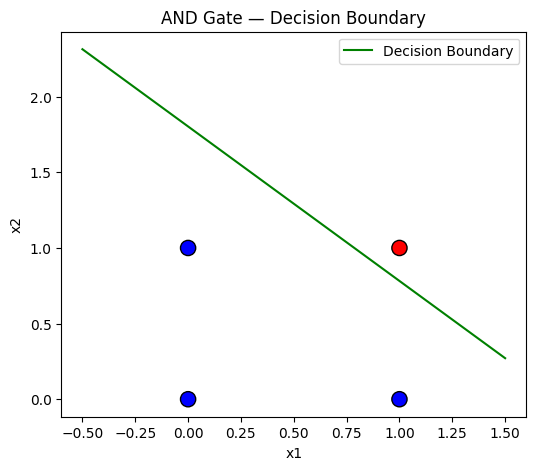

In [ ]:
# Decision boundary line-এর formula: w1*x1 + w2*x2 + b = 0  =>  x2 = -(w1*x1 + b)/w2
x1_vals = torch.linspace(-0.5, 1.5, 100)
x2_vals = -(w_and[0]*x1_vals + b_and) / w_and[1]

plt.figure(figsize=(6, 5))
plt.plot(x1_vals.numpy(), x2_vals.numpy(), 'g-', label="Decision Boundary")
colors = ['red' if y == 1 else 'blue' for y in Y_and]
plt.scatter(X_and[:,0], X_and[:,1], c=colors, s=120, edgecolor='black')
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("AND Gate — Decision Boundary")
plt.legend()
plt.show()
# red point (AND=1) সবসময় line-এর একপাশে, blue (AND=0) অন্যপাশে — এটাই perfect separation প্রমাণ করে


## B.5 Perceptron Learning Rule (কেন formula-টা কাজ করে সেটা step-by-step দেখা)

In [ ]:
# একটা misclassified point বারবার update করে দেখা prediction কীভাবে target-এর দিকে এগোয়
w = torch.tensor([0.3, 0.3])
b = torch.tensor(0.5)
eta = 0.5

x = torch.tensor([1.0, 1.0])
y_true = torch.tensor(0.0)   # target 0, কিন্তু শুরুর w,b দিয়ে prediction বেশি (misclassified)

for step in range(10):
    z = torch.dot(w, x) + b
    y_pred = torch.sigmoid(z)
    error = y_true - y_pred     # error সবসময় negative থাকবে (কারণ y_true=0, sigmoid সবসময় >0)

    print(f"Step {step}: y_pred={y_pred.item():.4f}, error={error.item():.4f}")

    w = w + eta * error * x     # negative error -> weight ক্রমাগত কমছে -> z কমছে -> y_pred কমছে (target-এর দিকে)
    b = b + eta * error


Step 0: y_pred=0.7503, error=-0.7503
Step 1: y_pred=0.4937, error=-0.4937
Step 2: y_pred=0.3174, error=-0.3174
Step 3: y_pred=0.2241, error=-0.2241
Step 4: y_pred=0.1711, error=-0.1711
Step 5: y_pred=0.1377, error=-0.1377
Step 6: y_pred=0.1149, error=-0.1149
Step 7: y_pred=0.0985, error=-0.0985
Step 8: y_pred=0.0862, error=-0.0862
Step 9: y_pred=0.0765, error=-0.0765


## B.6 Gradient Descent (Manual, একটা general loss function দিয়ে)

In [ ]:
# Simple linear model: y_pred = w * x (bias বাদ দিলাম simplicity-র জন্য)
w = torch.tensor(0.0)
x = torch.tensor(3.0)
y_true = torch.tensor(12.0)
lr = 0.05   # ছোট, stable learning rate (বড় lr দিলে diverge করতে পারে, আগে দেখা গেছে)

for step in range(8):
    y_pred = w * x
    loss = (y_pred - y_true) ** 2         # MSE loss (একটা sample-এর জন্য)

    # manual gradient: dLoss/dw = 2*(y_pred - y_true)*x  (calculus থেকে derive করা)
    grad = 2 * (y_pred - y_true) * x

    print(f"Step {step}: w={w.item():.4f}, y_pred={y_pred.item():.4f}, loss={loss.item():.4f}, grad={grad.item():.4f}")

    w = w - lr * grad   # gradient-এর উল্টো দিকে move করা হচ্ছে (loss কমানোর জন্য, তাই minus sign)

print(f"\nFinal w: {w.item():.4f} (target ছিল w=4.0, কারণ 4*3=12=y_true)")


Step 0: w=0.0000, y_pred=0.0000, loss=144.0000, grad=-72.0000
Step 1: w=3.6000, y_pred=10.8000, loss=1.4400, grad=-7.2000
Step 2: w=3.9600, y_pred=11.8800, loss=0.0144, grad=-0.7200
Step 3: w=3.9960, y_pred=11.9880, loss=0.0001, grad=-0.0720
Step 4: w=3.9996, y_pred=11.9988, loss=0.0000, grad=-0.0072
Step 5: w=4.0000, y_pred=11.9999, loss=0.0000, grad=-0.0007
Step 6: w=4.0000, y_pred=12.0000, loss=0.0000, grad=-0.0001
Step 7: w=4.0000, y_pred=12.0000, loss=0.0000, grad=-0.0000

Final w: 4.0000 (target ছিল w=4.0, কারণ 4*3=12=y_true)


## B.7 Perceptron Loss (max(0, -y*z) formula)

In [ ]:
# Perceptron loss: শুধু ভুল হলেই (misclassified) positive loss দেয়, সঠিক হলে loss = 0
# y_true এখানে +1/-1 format-এ (perceptron loss-এর convention অনুযায়ী)
pairs = [
    {'z': 3.0, 'y_true': 1.0},    # সঠিক (same sign) -> loss 0
    {'z': -2.0, 'y_true': 1.0},   # ভুল (opposite sign) -> loss > 0
    {'z': -1.5, 'y_true': -1.0},  # সঠিক
    {'z': 0.0, 'y_true': 1.0},    # boundary case
    {'z': 4.0, 'y_true': -1.0},   # সবচেয়ে বড় ভুল (confident wrong prediction)
]

for p in pairs:
    z = torch.tensor(p['z'])
    y_true = torch.tensor(p['y_true'])
    loss = torch.clamp(-y_true * z, min=0)   # max(0, -y*z)
    status = "Correct" if loss.item() == 0 else "Incorrect"
    print(f"z={p['z']:>5}, y_true={p['y_true']:>5} -> Loss={loss.item():.2f}  [{status}]")


z=  3.0, y_true=  1.0 -> Loss=0.00  [Correct]
z= -2.0, y_true=  1.0 -> Loss=2.00  [Incorrect]
z= -1.5, y_true= -1.0 -> Loss=0.00  [Correct]
z=  0.0, y_true=  1.0 -> Loss=-0.00  [Correct]
z=  4.0, y_true= -1.0 -> Loss=4.00  [Incorrect]


## B.8 Sigmoid (activation, derivative, saturation)

In [ ]:
z_values = torch.tensor([-10.0, -2.0, -0.5, 0.0, 0.5, 2.0, 10.0])
sigmoid_out = torch.sigmoid(z_values)               # output সবসময় 0-1 এর মধ্যে
derivative = sigmoid_out * (1 - sigmoid_out)         # sigmoid derivative formula: σ(z)*(1-σ(z))

for z, s, d in zip(z_values, sigmoid_out, derivative):
    print(f"z={z.item():>6.1f} -> sigmoid={s.item():.4f}, derivative={d.item():.4f}")

# লক্ষ্য করো: বড় |z| তে (extreme value) derivative প্রায় 0 — এটাই "saturation"
# saturation-এর কারণে বড় নেটওয়ার্কে backprop-এর সময় gradient প্রায় 0 হয়ে যায় (vanishing gradient)


z= -10.0 -> sigmoid=0.0000, derivative=0.0000
z=  -2.0 -> sigmoid=0.1192, derivative=0.1050
z=  -0.5 -> sigmoid=0.3775, derivative=0.2350
z=   0.0 -> sigmoid=0.5000, derivative=0.2500
z=   0.5 -> sigmoid=0.6225, derivative=0.2350
z=   2.0 -> sigmoid=0.8808, derivative=0.1050
z=  10.0 -> sigmoid=1.0000, derivative=0.0000


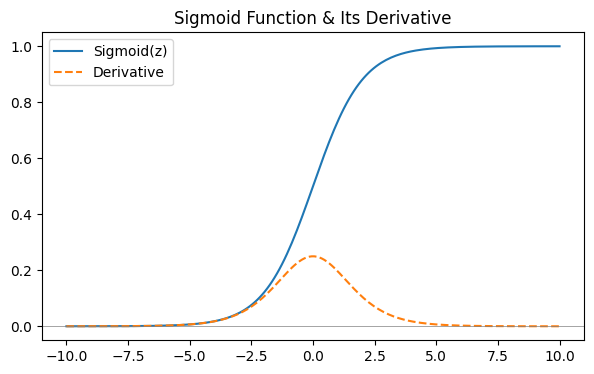

In [ ]:
# Sigmoid ফাংশনটা visually কেমন দেখতে, সেটা plot করা
z_range = torch.linspace(-10, 10, 200)
sig = torch.sigmoid(z_range)
deriv = sig * (1 - sig)

plt.figure(figsize=(7, 4))
plt.plot(z_range.numpy(), sig.numpy(), label="Sigmoid(z)")
plt.plot(z_range.numpy(), deriv.numpy(), label="Derivative", linestyle='--')
plt.axhline(0, color='gray', linewidth=0.5)
plt.title("Sigmoid Function & Its Derivative")
plt.legend()
plt.show()


## B.9 ReLU / Softmax

In [ ]:
# ---- ReLU: negative হলে 0, positive হলে same value ----
z_values = torch.tensor([-10.0, -2.0, -0.1, 0.0, 0.1, 2.0, 10.0])
relu_out = torch.relu(z_values)
print("ReLU input: ", z_values.tolist())
print("ReLU output:", relu_out.tolist())

# ---- Softmax: multi-class logits কে probability distribution-এ বদলানো ----
logits = torch.tensor([3.0, 1.0, 0.2, 0.1])   # 4-class-এর raw score
softmax_out = torch.softmax(logits, dim=0)
print("\nSoftmax input (logits):", logits.tolist())
print("Softmax output (probs): ", [round(p, 4) for p in softmax_out.tolist()])
print("Sum of probabilities:   ", softmax_out.sum().item(), "(সবসময় 1.0 হওয়ার কথা)")


ReLU input:  [-10.0, -2.0, -0.10000000149011612, 0.0, 0.10000000149011612, 2.0, 10.0]
ReLU output: [0.0, 0.0, 0.0, 0.0, 0.10000000149011612, 2.0, 10.0]

Softmax input (logits): [3.0, 1.0, 0.20000000298023224, 0.10000000149011612]
Softmax output (probs):  [0.7993, 0.1082, 0.0486, 0.044]
Sum of probabilities:    1.0 (সবসময় 1.0 হওয়ার কথা)


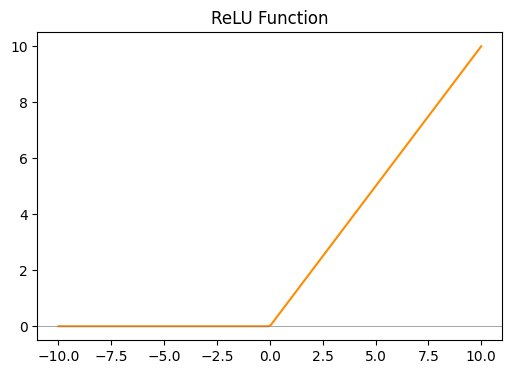

In [ ]:
# ReLU function visually plot করা
z_range = torch.linspace(-10, 10, 200)
relu_curve = torch.relu(z_range)

plt.figure(figsize=(6, 4))
plt.plot(z_range.numpy(), relu_curve.numpy(), color='darkorange')
plt.title("ReLU Function")
plt.axhline(0, color='gray', linewidth=0.5)
plt.show()


## B.10 Binary Cross Entropy (manual vs built-in)

In [ ]:
y_true = torch.tensor([1.0, 1.0, 0.0, 0.0])
y_pred = torch.tensor([0.95, 0.05, 0.1, 0.9])   # predicted probability

# ---- Manual BCE formula: -[y*log(p) + (1-y)*log(1-p)] ----
manual_bce = -(y_true * torch.log(y_pred) + (1 - y_true) * torch.log(1 - y_pred))
print("Manual BCE per sample:", manual_bce.tolist())
print("Manual BCE (mean):    ", manual_bce.mean().item())

# ---- PyTorch built-in function দিয়ে verify করা ----
builtin_bce = torch.nn.functional.binary_cross_entropy(y_pred, y_true)
print("Built-in BCE (mean):  ", builtin_bce.item())
print("Match:", torch.isclose(manual_bce.mean(), builtin_bce).item())

# লক্ষ্য করো: index 1-এ (y_true=1, কিন্তু y_pred মাত্র 0.05) loss সবচেয়ে বেশি
# কারণ log(p) যখন p->0-এর কাছে যায়, -log(p) অনেক বড় হয়ে যায় — confident ভুলকে কড়াভাবে penalty দেয়


Manual BCE per sample: [0.051293306052684784, 2.995732307434082, 0.10536054521799088, 2.3025848865509033]
Manual BCE (mean):     1.3637428283691406
Built-in BCE (mean):   1.3637428283691406
Match: True


## B.11 Forward / Backward Propagation (autograd দিয়ে, ছোট 2-layer network)

In [ ]:
layer1 = nn.Linear(2, 3)   # input(2) -> hidden(3)
layer2 = nn.Linear(3, 1)   # hidden(3) -> output(1)

x = torch.tensor([[1.0, 0.5]])
y_true = torch.tensor([[1.0]])

# ---- Forward pass: input থেকে output পর্যন্ত layer-by-layer গণনা ----
h = torch.relu(layer1(x))                 # hidden layer output (ReLU activation সহ)
output = torch.sigmoid(layer2(h))         # final output (sigmoid দিয়ে probability-তে convert)
loss = torch.nn.functional.binary_cross_entropy(output, y_true)
print("Loss (forward pass শেষে):", loss.item())

# ---- Backward pass: loss থেকে শুরু করে chain rule দিয়ে প্রতিটা layer-এর gradient বের করা ----
# .backward() call করলেই PyTorch পুরো computation graph-এ উল্টো দিকে গিয়ে
# প্রতিটা weight/bias-এর জন্য gradient বের করে ফেলে (autograd engine ব্যবহার করে)
loss.backward()

print("\nlayer1 weight gradient shape:", layer1.weight.grad.shape)
print("layer1 weight gradient:\n", layer1.weight.grad)
print("\nlayer2 weight gradient shape:", layer2.weight.grad.shape)
print("layer2 weight gradient:\n", layer2.weight.grad)


Loss (forward pass শেষে): 0.449790358543396

layer1 weight gradient shape: torch.Size([3, 2])
layer1 weight gradient:
 

tensor([[ 0.1534,  0.0767],
        [-0.1818, -0.0909],
        [-0.0391, -0.0196]])

layer2 weight gradient shape: torch.Size([1, 3])
layer2 weight gradient:
 tensor([[-0.1774, -0.2081, -0.1955]])


## B.12 Autograd (raw tensor দিয়ে, `nn.Linear` ছাড়া)

In [ ]:
# requires_grad=True দিলে PyTorch এই tensor-এর গণনার history track করে রাখে (computation graph বানায়)
x = torch.tensor(2.0, requires_grad=True)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b        # y = 3*2 + 1 = 7
loss = y ** 2         # loss = 49  (একটা simple function, যাতে derivative হাতে verify করা যায়)

loss.backward()       # backward call করলেই সব requires_grad=True tensor-এর gradient (.grad) বসে যায়

# হাতে calculus দিয়ে verify: loss = (w*x+b)^2
# dLoss/dw = 2*(w*x+b)*x = 2*7*2 = 28
# dLoss/db = 2*(w*x+b)*1 = 2*7*1 = 14
# dLoss/dx = 2*(w*x+b)*w = 2*7*3 = 42
print("dLoss/dw:", w.grad.item(), " (expected 28)")
print("dLoss/db:", b.grad.item(), " (expected 14)")
print("dLoss/dx:", x.grad.item(), " (expected 42)")


dLoss/dw: 28.0  (expected 28)
dLoss/db: 14.0  (expected 14)
dLoss/dx: 42.0  (expected 42)


---
# PART C — Full Project: Diabetes Prediction (Complete `nn.Module` Pipeline)

এখন Part A-এর dataset দিয়েই একটা সম্পূর্ণ, 'real training pipeline' বানানো হচ্ছে।
Part B-তে যা যা manually করেছ (weight update, gradient, forward/backward), সেগুলো
এখন `nn.Module` + optimizer এর ভেতরে automatic ভাবে ঘটবে।


## C.1 Preprocessing

In [ ]:
# Hidden missing value (0 হিসেবে লুকিয়ে থাকা) — Glucose, BloodPressure, SkinThickness,
# Insulin, BMI — এগুলোর 0 value আসলে "data নেই" বোঝায় (medically impossible value)
# তাই এগুলোকে column-এর median দিয়ে replace করা হচ্ছে (mean-এর চেয়ে median বেশি robust, outlier কম প্রভাব ফেলে)
cols_with_hidden_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_clean = df.copy()
for col in cols_with_hidden_missing:
    median_val = df_clean[df_clean[col] != 0][col].median()   # 0 বাদ দিয়ে median বের করা
    df_clean[col] = df_clean[col].replace(0, median_val)       # 0-কে median দিয়ে replace

print("Cleaning সম্পন্ন। নতুন 0-count চেক:")
print((df_clean[cols_with_hidden_missing] == 0).sum())


Cleaning সম্পন্ন। নতুন 0-count চেক:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [ ]:
# Features (X) এবং target (y) আলাদা করা
X = df_clean.drop(columns=['Outcome']).values   # সব feature column (8টা)
y = df_clean['Outcome'].values                   # target column (0/1)

# Train / Validation / Test split — 70% train, 15% val, 15% test
# stratify=y দেওয়া হচ্ছে যাতে প্রতিটা split-এ 0/1-এর proportion সমান থাকে
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)


Train: (537, 8)  Val: (115, 8)  Test: (116, 8)


In [ ]:
# Feature scaling — সব feature-কে mean=0, std=1 এ আনা হচ্ছে
# গুরুত্বপূর্ণ: scaler শুধু TRAIN data দিয়ে fit করা হয় (fit_transform),
# val/test-এ শুধু transform (fit না) — নাহলে data leakage হয়ে যাবে
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaling সম্পন্ন। Train data-র mean (আনুমানিক 0 হওয়ার কথা):", X_train_scaled.mean().round(4))
print("Train data-র std (আনুমানিক 1 হওয়ার কথা):", X_train_scaled.std().round(4))


Scaling সম্পন্ন। Train data-র mean (আনুমানিক 0 হওয়ার কথা): 0.0
Train data-র std (আনুমানিক 1 হওয়ার কথা): 1.0


## C.2 NumPy → PyTorch Tensor & DataLoader

In [ ]:
# numpy array-কে PyTorch tensor-এ convert করা
# dtype=torch.float32 ব্যবহার করা হচ্ছে কারণ PyTorch-এর layer/computation default এই type আশা করে
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
# y-কে reshape(-1,1) করা হচ্ছে যাতে shape [N] না হয়ে [N,1] হয়
# (BCELoss-এর output shape-এর সাথে মিলাতে হবে, যেটা [N,1] আকারে আসবে)
y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("X_train tensor shape:", X_train_t.shape)
print("y_train tensor shape:", y_train_t.shape)


X_train tensor shape: torch.Size([537, 8])
y_train tensor shape: torch.Size([537, 1])


In [ ]:
# TensorDataset — X এবং y-কে জোড়া বেঁধে একটা dataset object বানানো
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

# DataLoader — dataset-কে ছোট ছোট batch-এ ভাগ করে model-এ পাঠানোর জন্য
# batch_size=16 মানে প্রতিবার ১৬টা sample একসাথে যাবে (পুরো dataset একসাথে না দিয়ে)
# shuffle=True (train-এর জন্য) — প্রতি epoch-এ data-র order পাল্টে যায়, model যাতে order মুখস্থ না করে
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)   # validation-এ shuffle দরকার নেই

print("Number of training batches:", len(train_loader))


Number of training batches: 34


## C.3 Model Architecture (`nn.Module`, MLP)

In [ ]:
class DiabetesMLP(nn.Module):
    """
    3-layer MLP (Multi-Layer Perceptron):
    Input(8 feature) -> Hidden1(16) -> Hidden2(8) -> Output(1, probability)
    """
    def __init__(self, input_size):
        super().__init__()   # nn.Module-এর parent __init__ call করা বাধ্যতামূলক, নাহলে layer register হবে না

        self.layer1 = nn.Linear(input_size, 16)   # input -> hidden1
        self.layer2 = nn.Linear(16, 8)             # hidden1 -> hidden2
        self.output_layer = nn.Linear(8, 1)        # hidden2 -> output (1 value, diabetes probability)

        self.relu = nn.ReLU()          # hidden layer-গুলোর পর non-linearity যোগ করার জন্য
        self.sigmoid = nn.Sigmoid()    # শেষ layer-এর পর output-কে 0-1 probability-তে আনার জন্য
        self.dropout = nn.Dropout(0.2) # training-এর সময় randomly 20% neuron বন্ধ রাখে (overfitting কমাতে)

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.dropout(x)            # শুধু training mode-এ সক্রিয়, eval mode-এ automatically বন্ধ
        x = self.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.sigmoid(self.output_layer(x))   # final probability output
        return x

# Model object তৈরি করা — এখানেই PyTorch automatically সব weight/bias random initialize করে দেয়
model = DiabetesMLP(input_size=X_train.shape[1])
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("\nTotal trainable parameters:", total_params)


DiabetesMLP(
  (layer1): Linear(in_features=8, out_features=16, bias=True)
  (layer2): Linear(in_features=16, out_features=8, bias=True)
  (output_layer): Linear(in_features=8, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
  (dropout): Dropout(p=0.2, inplace=False)
)

Total trainable parameters: 289


In [ ]:
# Model-এর initial (random) weight/bias দেখা
for name, param in model.named_parameters():
    print(f"{name}: shape={tuple(param.shape)}")


layer1.weight: shape=(16, 8)
layer1.bias: shape=(16,)
layer2.weight: shape=(8, 16)
layer2.bias: shape=(8,)
output_layer.weight: shape=(1, 8)
output_layer.bias: shape=(1,)


## C.4 Loss Function ও Optimizer

In [ ]:
# Binary classification হওয়ায় BCELoss ব্যবহার করা হচ্ছে
# (আমাদের model-এর শেষে আগে থেকেই Sigmoid বসানো আছে, তাই BCELoss ঠিক আছে —
#  BCEWithLogitsLoss ব্যবহার করলে model-এ Sigmoid বসানো লাগত না, কিন্তু আমরা explicit রাখলাম শেখার সুবিধার্থে)
criterion = nn.BCELoss()

# Adam optimizer — gradient-based automatic weight update করে
# weight_decay একটা ছোট L2 regularization যোগ করে, overfitting কমাতে সাহায্য করে
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)

EPOCHS = 150


## C.5 Complete Training Loop

In [ ]:
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(1, EPOCHS + 1):
    # ---------------- Training phase ----------------
    model.train()   # dropout সক্রিয় থাকবে (training mode)
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()                  # আগের batch-এর gradient মুছে ফেলা (accumulate ঠেকাতে)
        prediction = model(X_batch)            # forward propagation
        loss = criterion(prediction, y_batch)  # loss calculate
        loss.backward()                        # backward propagation (autograd + chain rule দিয়ে gradient বের করা)
        optimizer.step()                       # gradient অনুযায়ী সব weight/bias update করা

        running_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # ---------------- Validation phase ----------------
    model.eval()   # dropout বন্ধ (পুরো network ব্যবহার হবে, evaluation-এর জন্য এটাই সঠিক)
    val_running_loss = 0.0
    correct = 0

    with torch.no_grad():   # gradient হিসাব বন্ধ রাখা হচ্ছে (evaluation-এ দরকার নেই, memory/speed বাঁচে)
        for X_batch, y_batch in val_loader:
            prediction = model(X_batch)
            loss = criterion(prediction, y_batch)
            val_running_loss += loss.item() * X_batch.size(0)

            predicted_class = (prediction >= 0.5).float()   # 0.5 threshold দিয়ে probability -> class (0/1)
            correct += (predicted_class == y_batch).sum().item()

    epoch_val_loss = val_running_loss / len(val_dataset)
    epoch_val_acc = correct / len(val_dataset)
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    if epoch % 15 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{EPOCHS} | Train Loss: {epoch_train_loss:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc*100:.2f}%")


Epoch   1/150 | Train Loss: 0.6579 | Val Loss: 0.6423 | Val Acc: 65.22%


Epoch  15/150 | Train Loss: 0.4752 | Val Loss: 0.5226 | Val Acc: 72.17%


Epoch  30/150 | Train Loss: 0.4533 | Val Loss: 0.5188 | Val Acc: 71.30%


Epoch  45/150 | Train Loss: 0.4433 | Val Loss: 0.5129 | Val Acc: 71.30%


Epoch  60/150 | Train Loss: 0.4403 | Val Loss: 0.5128 | Val Acc: 72.17%


...

Epoch  90/150 | Train Loss: 0.4339 | Val Loss: 0.5061 | Val Acc: 69.57%


Epoch 105/150 | Train Loss: 0.4448 | Val Loss: 0.5007 | Val Acc: 72.17%


Epoch 120/150 | Train Loss: 0.4221 | Val Loss: 0.5099 | Val Acc: 72.17%


Epoch 135/150 | Train Loss: 0.4254 | Val Loss: 0.5084 | Val Acc: 73.04%


Epoch 150/150 | Train Loss: 0.4165 | Val Loss: 0.5133 | Val Acc: 73.04%


In [ ]:
# একটা batch-এর gradient sample হিসেবে দেখা (Part B.11-এর মতোই, কিন্তু এখানে full model-এ)
for name, param in model.named_parameters():
    if param.grad is not None:
        print(f"{name}: grad shape={tuple(param.grad.shape)}, grad mean={param.grad.mean().item():.6f}")


layer1.weight: grad shape=(16, 8), grad mean=-0.002363
layer1.bias: grad shape=(16,), grad mean=-0.008671
layer2.weight: grad shape=(8, 16), grad mean=-0.002797
layer2.bias: grad shape=(8,), grad mean=-0.008849
output_layer.weight: grad shape=(1, 8), grad mean=0.034467
output_layer.bias: grad shape=(1,), grad mean=0.107434


## C.6 Training Curve Visualization (Complex DL Visualization #1)

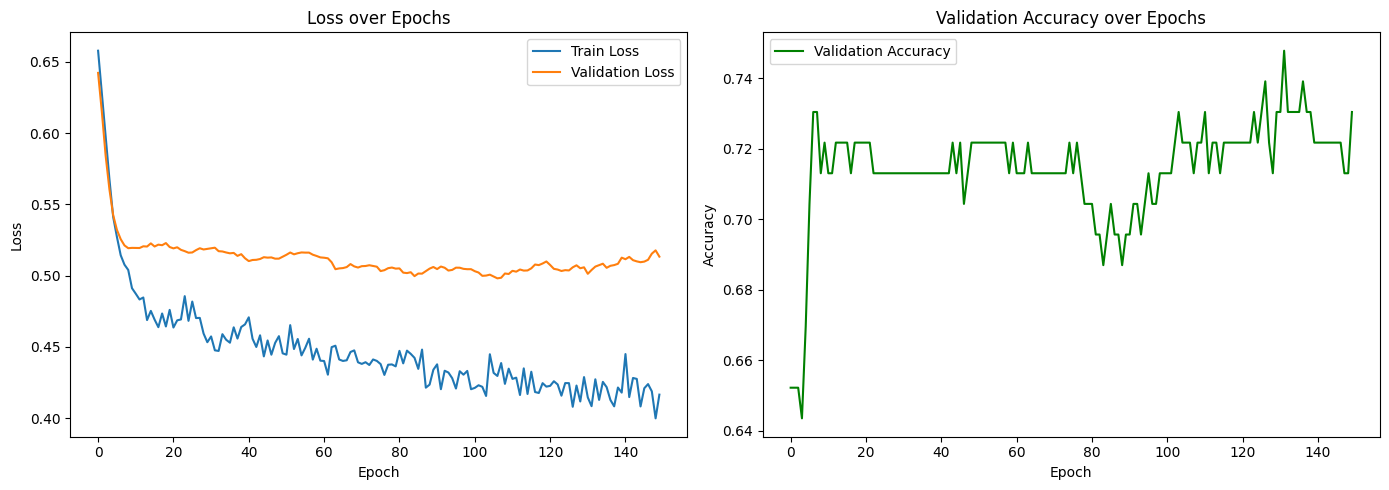

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label="Train Loss")
axes[0].plot(val_losses, label="Validation Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Loss over Epochs")
axes[0].legend()

axes[1].plot(val_accuracies, color='green', label="Validation Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Validation Accuracy over Epochs")
axes[1].legend()

plt.tight_layout()
plt.show()


## C.7 Decision Boundary Visualization via PCA (Complex DL Visualization #2)

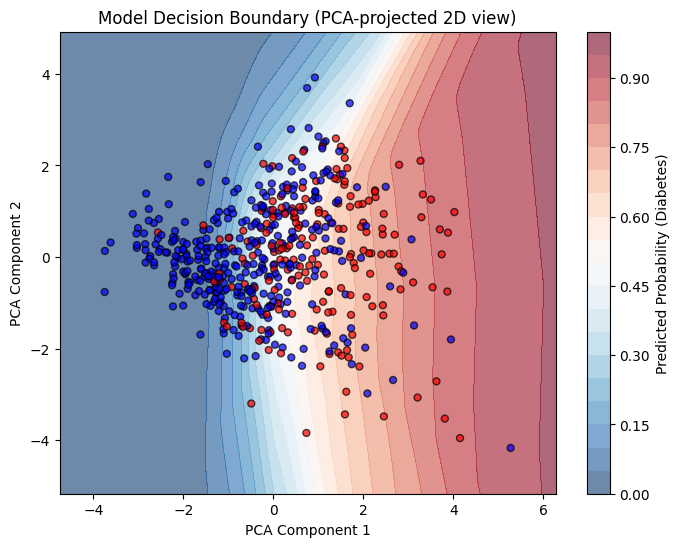

In [ ]:
# Model-টা 8-dimensional feature space-এ কাজ করে, যা সরাসরি চোখে দেখা যায় না।
# তাই PCA দিয়ে সেই 8D space-কে 2D-তে projection করে, model-এর decision boundary
# আনুমানিকভাবে visualize করা হচ্ছে (এটা exact না, কিন্তু pattern বোঝার জন্য useful)

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

# 2D grid বানানো, PCA space-এর প্রতিটা point-এ model কী predict করে সেটা দেখার জন্য
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
grid_2d = np.c_[xx.ravel(), yy.ravel()]

# grid-এর 2D point গুলোকে আবার original 8D space-এ ফিরিয়ে নেওয়া (PCA inverse_transform দিয়ে)
# — কারণ আমাদের model 8D input আশা করে, 2D না
grid_original_space = pca.inverse_transform(grid_2d)
grid_tensor = torch.tensor(grid_original_space, dtype=torch.float32)

model.eval()
with torch.no_grad():
    grid_predictions = model(grid_tensor).numpy().reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, grid_predictions, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(label="Predicted Probability (Diabetes)")
scatter_colors = ['blue' if label == 0 else 'red' for label in y_train]
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=scatter_colors, edgecolor='black', s=25, alpha=0.7)
plt.xlabel("PCA Component 1"); plt.ylabel("PCA Component 2")
plt.title("Model Decision Boundary (PCA-projected 2D view)")
plt.show()


## C.8 Test Set Evaluation

In [ ]:
model.eval()
with torch.no_grad():
    test_probabilities = model(X_test_t)
    test_predictions = (test_probabilities >= 0.5).float()

y_true_np = y_test_t.numpy()
y_pred_np = test_predictions.numpy()
y_prob_np = test_probabilities.numpy()

accuracy = accuracy_score(y_true_np, y_pred_np)
precision = precision_score(y_true_np, y_pred_np, zero_division=0)
recall = recall_score(y_true_np, y_pred_np, zero_division=0)
f1 = f1_score(y_true_np, y_pred_np, zero_division=0)

print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall   : {recall*100:.2f}%")
print(f"F1 Score : {f1*100:.2f}%")


Accuracy : 76.72%
Precision: 71.88%
Recall   : 56.10%
F1 Score : 63.01%


## C.9 Confusion Matrix (Complex DL Visualization #3)

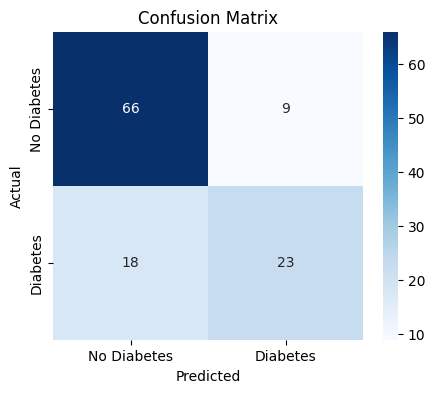

In [ ]:
cm = confusion_matrix(y_true_np, y_pred_np)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'], yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## C.10 ROC Curve (Complex DL Visualization #4)

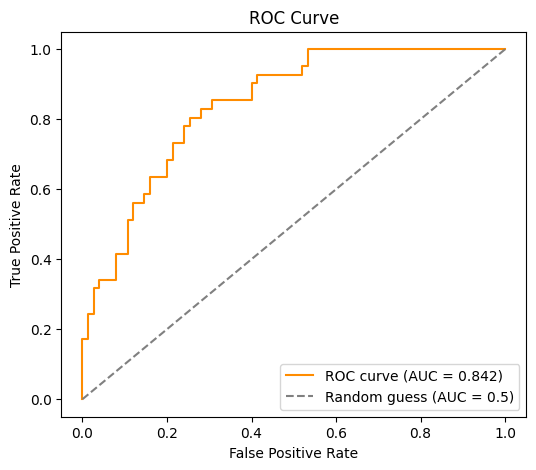

In [ ]:
# ROC Curve — বিভিন্ন threshold-এ model কতটা ভালো class আলাদা করতে পারছে তা দেখায়
# AUC (Area Under Curve) যত 1.0-এর কাছে, model তত ভালো (0.5 মানে random guessing-এর সমান)
fpr, tpr, thresholds = roc_curve(y_true_np, y_prob_np)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


## C.11 Model Save

In [ ]:
# Model-এর trained weight (state_dict) সেভ করা হচ্ছে — পুরো object না, শুধু parameter
# এটাই PyTorch-এর recommended, portable উপায়
torch.save(model.state_dict(), "diabetes_mlp_model.pth")

# scaler ও সেভ করা দরকার, কারণ নতুন data দিয়ে prediction করার সময় একই scaling apply করতে হবে
import joblib
joblib.dump(scaler, "diabetes_scaler.pkl")

print("Model ও scaler সফলভাবে সেভ হয়েছে।")


Model ও scaler সফলভাবে সেভ হয়েছে।


---
## Summary

- **Part A**: real dataset (Diabetes) দিয়ে EDA + visualization
- **Part B**: প্রতিটা fundamental DL concept (Perceptron → Autograd) আলাদা করে, ছোট example দিয়ে demonstrate করা হয়েছে
- **Part C**: একই real dataset দিয়ে একটা সম্পূর্ণ `nn.Module` pipeline — Part B-এর manual concept-গুলোই এখানে automatic ভাবে কাজ করছে (`loss.backward()` = autograd + chain rule, `optimizer.step()` = weight update, ইত্যাদি)

**মূল শিক্ষা:** Part B বুঝলে Part C-এর প্রতিটা লাইন (`loss.backward()`, `optimizer.step()`) এর ভেতরে কী ঘটছে তা তুমি জানো — এটাই "black box" না ভেবে deep learning বোঝার key।
